In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing  import StandardScaler

from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import(classification_report,confusion_matrix,roc_auc_score,precision_recall_curve,average_precision_score)

from imblearn.over_sampling import SMOTE

import shap

import warnings
warnings.filterwarnings("ignore")


In [5]:
df=pd.read_csv("credit_card_fraud_10k.csv")
print(df.shape)
df.head()

(10000, 10)


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


is_fraud
0    9849
1     151
Name: count, dtype: int64


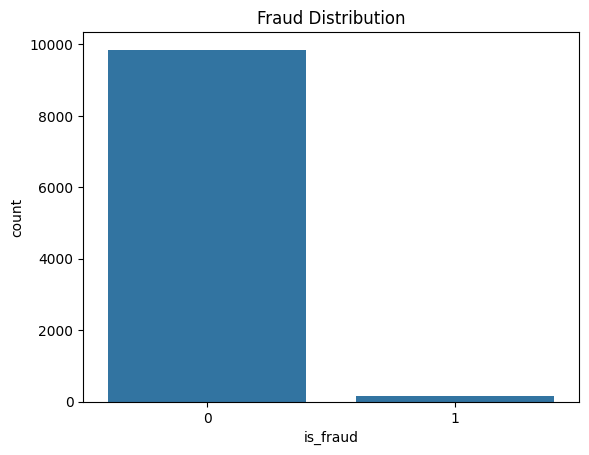

In [6]:
print(df["is_fraud"].value_counts())
sns.countplot(x="is_fraud",data=df)
plt.title("Fraud Distribution")
plt.show()

In [7]:
X=df.drop("is_fraud",axis=1)
y=df["is_fraud"]

In [8]:
X=pd.get_dummies(X,columns=["merchant_category"],drop_first=True)


In [10]:
X.head()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,merchant_category_Electronics,merchant_category_Food,merchant_category_Grocery,merchant_category_Travel
0,1,84.47,22,0,0,66,3,40,True,False,False,False
1,2,541.82,3,1,0,87,1,64,False,False,False,True
2,3,237.01,17,0,0,49,1,61,False,False,True,False
3,4,164.33,4,0,1,72,3,34,False,False,True,False
4,5,30.53,15,0,0,79,0,44,False,True,False,False


In [12]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

In [13]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [14]:
smote=SMOTE(random_state=42)
X_train_smote,y_train_smote=smote.fit_resample(X_train_scaled,y_train)
print("Before SMOTE")
print(y_train.value_counts())
print("\nAfter SMOTE")
print(pd.Series(y_train_smote).value_counts())

Before SMOTE
is_fraud
0    7879
1     121
Name: count, dtype: int64

After SMOTE
is_fraud
0    7879
1    7879
Name: count, dtype: int64


In [15]:
svm = SVC(
    kernel='rbf',
    probability=True,
    class_weight='balanced',
    random_state=42
)

svm.fit(
    X_train_smote,
    y_train_smote
)

svm_pred = svm.predict(X_test_scaled)

print(classification_report(
    y_test,
    svm_pred
))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      1970
           1       0.40      0.80      0.53        30

    accuracy                           0.98      2000
   macro avg       0.70      0.89      0.76      2000
weighted avg       0.99      0.98      0.98      2000



In [16]:
xgb = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)

xgb.fit(
    X_train_smote,
    y_train_smote
)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBR

In [17]:
xgb_pred=xgb.predict(X_test_scaled)
print(classification_report(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1970
           1       0.77      1.00      0.87        30

    accuracy                           1.00      2000
   macro avg       0.88      1.00      0.93      2000
weighted avg       1.00      1.00      1.00      2000



In [19]:
xgb_prob=xgb.predict_proba(X_test_scaled)[:,1]
auc=roc_auc_score(y_test,xgb_prob)
print("ROC AUC =",auc)

ROC AUC = 0.9994585448392554


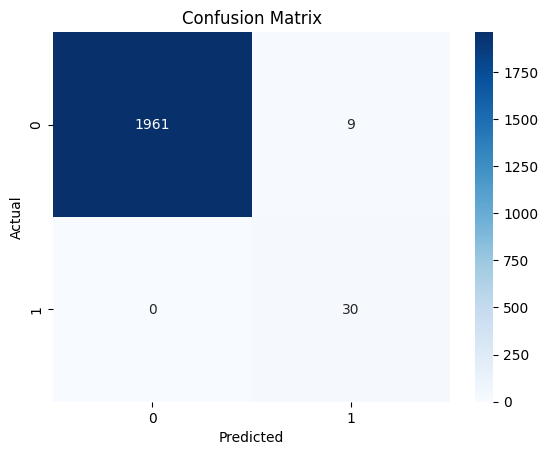

In [20]:
cm=confusion_matrix(y_test,xgb_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [21]:
importance = pd.DataFrame({

    "Feature": X.columns,
    "Importance": xgb.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(10))

                          Feature  Importance
2                transaction_hour    0.253189
4               location_mismatch    0.195070
5              device_trust_score    0.177404
3             foreign_transaction    0.153585
6               velocity_last_24h    0.096387
1                          amount    0.030271
11       merchant_category_Travel    0.018128
9          merchant_category_Food    0.016730
10      merchant_category_Grocery    0.015764
8   merchant_category_Electronics    0.015659


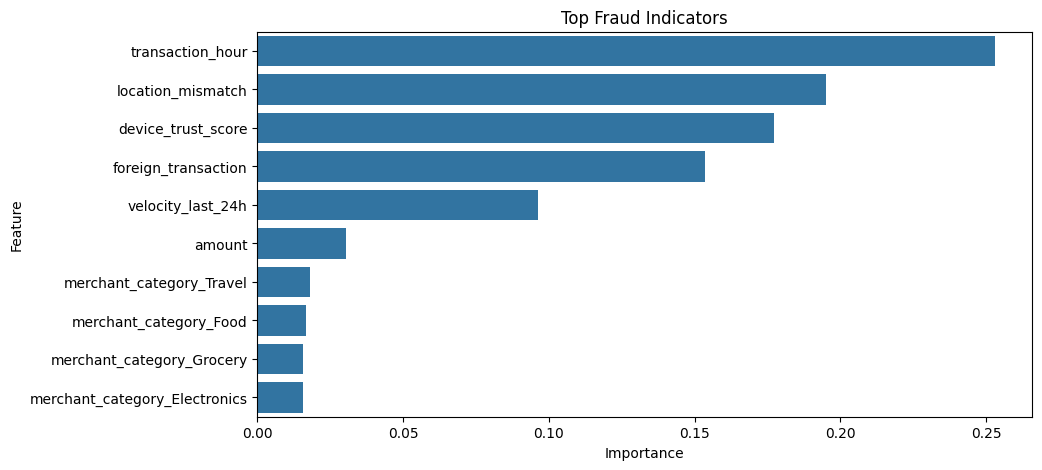

In [22]:
plt.figure(figsize=(10,5))
sns.barplot(data=importance.head(10),x="Importance",y="Feature")
plt.title("Top Fraud Indicators")
plt.show()

In [23]:
from sklearn.metrics import precision_score,recall_score

In [25]:
for threshold in [0.1,0.2,0.3,0.4,0.5,0.6]:
    pred=(xgb_prob>=threshold).astype(int)
    precision=precision_score(y_test,pred)
    recall=recall_score(y_test,pred)
    print(
        f"Threshold={threshold:.1f}"
        f"Precision={precision:.3f}"
        f"Recall={recall:.3f}"
    )

Threshold=0.1Precision=0.423Recall=1.000
Threshold=0.2Precision=0.556Recall=1.000
Threshold=0.3Precision=0.682Recall=1.000
Threshold=0.4Precision=0.750Recall=1.000
Threshold=0.5Precision=0.769Recall=1.000
Threshold=0.6Precision=0.811Recall=1.000
